### Notebook 4b — Classifier Training for the Six Scenarios

> Fine-tunes a DenseNet-121 (TorchXRayVision) for pneumonia vs No Finding under each scenario, with several random seeds, and saves the predicted probabilities on the real validation and test sets for the final evaluation notebook.

**Inputs to attach**: the output of Notebook 4a, or a Dataset made from it (the image cache). If that cannot be mounted, attach instead the inputs of Notebook 4a (NIH dataset, outputs of Notebooks 2, 3c and the two 3b runs) and the cache is built here (+7-10 min). Turn on a GPU and Internet.

**Scenarios** (`RUN` selects which ones are trained in this session)

| Name | Training set |
|---|---|
| `S1` | Real 5K (baseline) |
| `S2` | DC-GAN only: 2,500 pneumonia + 2,500 No Finding |
| `S3` | Real 5K + 5,000 DC-GAN pneumonia |
| `S4` | RoentGen-v2 only: 2,500 pneumonia + 2,500 No Finding |
| `S5` | Real 5K + 5,000 RoentGen-v2 pneumonia |
| `S6` | Real 10K (contains the 5K) |
| `S3-dose1000`, `S3-dose2500`, `S5-dose…` | as `S3` / `S5` with 1,000 or 2,500 synthetic pneumonia images |
| `S3-bal`, `S5-bal` | as `S3` / `S5` plus 2,500 synthetic No Finding images (removes "synthetic = pneumonia" as a shortcut) |

**Same for every scenario**: architecture, optimiser, augmentations, preprocessing, class-balanced sampler, training budget (at most 16 "epochs" of 150 batches), early stopping on the AUROC of the full real validation set, and the decision threshold (Youden index on that set). Nothing is selected on the test sets.

**Saved** (`/kaggle/working`): `preds/<scenario>_seed<k>.csv.gz` (probabilities on `val`, `test` and on the synthetic No Finding images that were not used in training), `curves/…csv` (per-epoch log) and `runs_summary.csv`.

### 1. Configuration

In [1]:
import os, time, math, random, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')

# ---------------- what to run ----------------
RUN   = ['S1', 'S2', 'S3', 'S4', 'S5', 'S6']      # add 'S3-bal', 'S5-bal', 'S3-dose1000', ... for the ablations
SEEDS = [0, 1, 2]
SKIP_EXISTING = True                              # skip runs whose predictions are already saved (useful after a crash in an interactive session)

# ---------------- model and training (identical for all scenarios) ----------------
WEIGHTS  = 'densenet121-res224-chex'              # CheXpert-only weights: not trained on NIH ChestX-ray14 (no test-set contamination) nor on MIMIC-CXR (RoentGen's data)
BATCH, STEPS_PER_EPOCH, MAX_EPOCHS, PATIENCE = 32, 150, 16, 4
LR, WD, WARMUP = 1e-4, 1e-4, 100
NORMALISE = True       # per-image percentile rescaling (1st-99th) applied to ALL images, real and synthetic, in training and test
RES_AUG   = True       # real training images are blurred to 128 px and back with probability 0.5 (the DC-GAN works at 128 px); never applied to test images

# ---------------- paths ----------------
INPUT_ROOT, WORK = '/kaggle/input', Path('/kaggle/working')
for d in ('preds', 'curves'): (WORK / d).mkdir(exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Enable a GPU accelerator (Settings -> Accelerator)'
print('GPU:', torch.cuda.get_device_name(0))
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

CACHE = None
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']
    if 'real_10k.npy' in files: CACHE = Path(cur); break
print('CACHE =', CACHE if CACHE else 'not attached -> it will be built in section 2 from the raw inputs')

GPU: Tesla T4
CACHE = not attached -> it will be built in section 2 from the raw inputs


### 2. Data

All arrays (224 × 224, uint8) come from Notebook 4a. `real_5k` is the `in_5k` subset of `real_10k`. Validation and test sets are the *full* versions (they include the other-disease hard negatives); the *clean* subsets are flagged with `clean`.

### 2a. Image Cache (built here if Notebook 4a is not attached)

If the output of Notebook 4a (or a Dataset made from it) is attached, it is used as it is. Otherwise the cache is built now, in the temporary disk (`/kaggle/temp`, not saved in the output), from the raw inputs: the NIH dataset, the output of Notebook 2, the output of Notebook 3c and the outputs of the two Notebook 3b runs. It takes about 7-10 minutes.

In [2]:
CACHE_BUILDER = r"""
import os, time, math
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SIZE = 224
INPUT_ROOT, CACHE = '/kaggle/input', Path('/kaggle/temp/cache')
CACHE.mkdir(parents=True, exist_ok=True)
WORKERS = 8

ALL_FILES = []
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']          # NIH image folders are not listed (their paths come from the CSV files)
    ALL_FILES += [os.path.join(cur, f) for f in files]
by_name = lambda nm: [p for p in ALL_FILES if os.path.basename(p) == nm]

h = by_name('real_10k.csv');                  assert h, 'real_10k.csv not found: attach the output of Notebook 2'
SPLITS_DIR = os.path.dirname(h[0])
h = by_name('synthetic_final_manifest.csv');  assert h, 'synthetic_final_manifest.csv not found: attach the output of Notebook 3c'
MANIFEST = h[0]
PNG = {os.path.basename(p): p for p in ALL_FILES if p.endswith('.png')}
print('SPLITS_DIR =', SPLITS_DIR); print('MANIFEST   =', MANIFEST); print(f'{len(PNG):,} synthetic PNG files found')
def load_real(p):
    return np.asarray(Image.open(p).convert('L').resize((SIZE, SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)

def cache_array(name, paths):
    paths = list(paths); arr = np.lib.format.open_memmap(CACHE / f'{name}.npy', mode='w+', dtype=np.uint8, shape=(len(paths), SIZE, SIZE))
    t0 = time.time(); step = 2000
    with ThreadPoolExecutor(WORKERS) as ex:
        for i in range(0, len(paths), step):
            arr[i:i + step] = np.stack(list(ex.map(load_real, paths[i:i + step])))
            print(f'  {name}: {min(i + step, len(paths)):,}/{len(paths):,}  ({time.time() - t0:.0f} s)', end='\r')
    arr.flush(); print(f'\n{name}: {arr.shape} saved ({time.time() - t0:.0f} s)'); return arr

r5, r10 = pd.read_csv(f'{SPLITS_DIR}/real_5k.csv'), pd.read_csv(f'{SPLITS_DIR}/real_10k.csv')
assert set(r5['image']) <= set(r10['image']), 'real_5k must be a subset of real_10k'
r10['in_5k'] = r10['image'].isin(set(r5['image']))
vf, vc = pd.read_csv(f'{SPLITS_DIR}/real_val_full.csv'), pd.read_csv(f'{SPLITS_DIR}/real_val_clean.csv')
tf, tc = pd.read_csv(f'{SPLITS_DIR}/real_test_full.csv'), pd.read_csv(f'{SPLITS_DIR}/real_test_clean.csv')
vf['clean'] = vf['image'].isin(set(vc['image'])); tf['clean'] = tf['image'].isin(set(tc['image']))
assert not (set(r10['Patient ID']) & set(vf['Patient ID'])) and not (set(r10['Patient ID']) & set(tf['Patient ID'])) and not (set(vf['Patient ID']) & set(tf['Patient ID'])), 'patient leakage between splits'
for d in (r10, vf, tf): assert set(d['label'].unique()) <= {0, 1}, 'unexpected labels'
print(f"real_10k {len(r10):,} (5K subset {int(r10.in_5k.sum()):,}) | val_full {len(vf):,} (clean {int(vf.clean.sum()):,}) | test_full {len(tf):,} (clean {int(tf.clean.sum()):,})")

for name, d in [('real_10k', r10), ('val_full', vf), ('test_full', tf)]:
    assert os.path.exists(d['path'].iloc[0]), 'NIH image path not found: attach the ChestX-ray14 dataset as input'
    cache_array(name, d['path']); d.to_csv(CACHE / f'{name}_index.csv', index=False)
man = pd.read_csv(MANIFEST); man = man[~man['degenerate'].astype(bool)].copy()
man['index'] = man['image'].str.extract(r'_(\d+)\.png')[0].astype(int)
for g, gname in [('dcgan', 'dcgan'), ('roentgen_v2', 'roentgen')]:
    d = man[man.generator == g].sort_values(['label', 'index'], ascending=[False, True]).reset_index(drop=True)
    d['path'] = d['image'].map(PNG); assert d['path'].notna().all(), f'{int(d.path.isna().sum())} {g} PNG files not found: attach the missing outputs'
    assert (d.label == 1).sum() == 5000 and (d.label == 0).sum() == 2500, f'unexpected image counts for {g}: {d.label.value_counts().to_dict()}'
    cache_array(gname, d['path'])
    d[['image', 'label', 'generator', 'subset', 'index', 'source', 'checkpoint']].to_csv(CACHE / f'{gname}_index.csv', index=False)
    print(d.groupby(['label', 'subset']).size().rename('images').to_string(), '\n') """
if CACHE is None:
    print('Building the image cache (about 7-10 min)...')
    exec(compile(CACHE_BUILDER, 'cache_builder', 'exec'), globals())
    CACHE = Path('/kaggle/temp/cache')
print('CACHE =', CACHE)

Building the image cache (about 7-10 min)...
SPLITS_DIR = /kaggle/input/notebooks/anafarr/02-cohort-definition-and-splits/splits
MANIFEST   = /kaggle/input/notebooks/anafarr/03c-quality-final-dataset/synthetic_final_manifest.csv
15,005 synthetic PNG files found
real_10k 10,000 (5K subset 5,000) | val_full 15,100 (clean 8,915) | test_full 25,592 (clean 10,415)
  real_10k: 10,000/10,000  (83 s)
real_10k: (10000, 224, 224) saved (83 s)
  val_full: 15,100/15,100  (124 s)
val_full: (15100, 224, 224) saved (125 s)
  test_full: 25,592/25,592  (208 s)
test_full: (25592, 224, 224) saved (208 s)
  dcgan: 7,500/7,500  (8 s)
dcgan: (7500, 224, 224) saved (9 s)
label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500 

  roentgen: 7,500/7,500  (21 s)
roentgen: (7500, 224, 224) saved (21 s)
label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500 

CACHE = /kaggle/temp/cache


In [3]:
ld = lambda nm: (np.load(CACHE / f'{nm}.npy'), pd.read_csv(CACHE / f'{nm}_index.csv'))
X10, I10 = ld('real_10k'); XV, IV = ld('val_full'); XT, IT = ld('test_full'); XG, IG = ld('dcgan'); XR, IR = ld('roentgen')
SYN = {'dcgan': (XG, IG), 'roentgen': (XR, IR)}
print(f'real_10k {X10.shape} | val_full {XV.shape} (pos {int(IV.label.sum())}) | test_full {XT.shape} (pos {int(IT.label.sum())}) | dcgan {XG.shape} | roentgen {XR.shape}')

SCENARIOS = {'S1': dict(real='5k'), 'S2': dict(syn='dcgan', n_pos=2500, n_neg=2500), 'S3': dict(real='5k', syn='dcgan', n_pos=5000),
             'S4': dict(syn='roentgen', n_pos=2500, n_neg=2500), 'S5': dict(real='5k', syn='roentgen', n_pos=5000), 'S6': dict(real='10k')}
for g, s in (('dcgan', 'S3'), ('roentgen', 'S5')):
    for k in (1000, 2500): SCENARIOS[f'{s}-dose{k}'] = dict(real='5k', syn=g, n_pos=k)
    SCENARIOS[f'{s}-bal'] = dict(real='5k', syn=g, n_pos=5000, n_neg=2500)

def build_train(cfg):
    """Returns uint8 images, labels and a flag 'is synthetic' for one scenario."""
    xs, ys, sy = [], [], []
    if cfg.get('real'):
        m = np.ones(len(I10), bool) if cfg['real'] == '10k' else I10['in_5k'].values
        xs.append(X10[m]); ys.append(I10.label.values[m]); sy.append(np.zeros(m.sum(), bool))
    if cfg.get('syn'):
        X, I = SYN[cfg['syn']]
        for lab, k in ((1, cfg.get('n_pos', 0)), (0, cfg.get('n_neg', 0))):
            m = ((I.label == lab) & (I['index'] < k)).values
            if m.sum(): xs.append(X[m]); ys.append(I.label.values[m]); sy.append(np.ones(m.sum(), bool))
    return np.concatenate(xs), np.concatenate(ys).astype(np.float32), np.concatenate(sy)

for k, cfg in SCENARIOS.items():
    x, y, s = build_train(cfg)
    print(f'{k:12s} n={len(y):6d} | pneumonia {int(y.sum()):5d} ({100 * s[y == 1].mean() if y.sum() else 0:3.0f}% synthetic) | No Finding {int((y == 0).sum()):5d} ({100 * s[y == 0].mean() if (y == 0).sum() else 0:3.0f}% synthetic)')
    del x

real_10k (10000, 224, 224) | val_full (15100, 224, 224) (pos 166) | test_full (25592, 224, 224) (pos 554) | dcgan (7500, 224, 224) | roentgen (7500, 224, 224)
S1           n=  5000 | pneumonia   683 (  0% synthetic) | No Finding  4317 (  0% synthetic)
S2           n=  5000 | pneumonia  2500 (100% synthetic) | No Finding  2500 (100% synthetic)
S3           n= 10000 | pneumonia  5683 ( 88% synthetic) | No Finding  4317 (  0% synthetic)
S4           n=  5000 | pneumonia  2500 (100% synthetic) | No Finding  2500 (100% synthetic)
S5           n= 10000 | pneumonia  5683 ( 88% synthetic) | No Finding  4317 (  0% synthetic)
S6           n= 10000 | pneumonia   683 (  0% synthetic) | No Finding  9317 (  0% synthetic)
S3-dose1000  n=  6000 | pneumonia  1683 ( 59% synthetic) | No Finding  4317 (  0% synthetic)
S3-dose2500  n=  7500 | pneumonia  3183 ( 79% synthetic) | No Finding  4317 (  0% synthetic)
S3-bal       n= 12500 | pneumonia  5683 ( 88% synthetic) | No Finding  6817 ( 37% synthetic)
S5-d

### 3. Preprocessing and Augmentation (on the GPU)

* **Common to all images**: per-image rescaling between the 1st and 99th percentile of intensity (`NORMALISE`), which removes the global brightness/contrast offsets between the real and synthetic images, and then the XRV input range [-1024, 1024].
* **Training only**: random rotation (±10°), scale (±10%), translation (±5%), gamma (0.8-1.25), and, for real images only, a random 128-px blur (`RES_AUG`).
* Test, validation and the synthetic No Finding check images get only the common rescaling.

In [4]:
def rescale(x):                                                   # per-image percentile rescaling to [0, 1]
    f = x.flatten(1).float(); lo, hi = torch.quantile(f, 0.01, dim=1, keepdim=True), torch.quantile(f, 0.99, dim=1, keepdim=True)
    return ((f - lo) / (hi - lo + 1e-6)).clamp(0, 1).view_as(x)

def affine(x):
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(10); sc = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.1
    tx, ty = (torch.rand(B, device=dev) * 2 - 1) * 0.1, (torch.rand(B, device=dev) * 2 - 1) * 0.1      # 5% of the width in [-1, 1] coordinates
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode='border', align_corners=False)

def degrade(x, is_syn):                                           # real images only: 224 -> 128 -> 224 with probability 0.5
    low = F.interpolate(F.interpolate(x, size=128, mode='bilinear', antialias=True, align_corners=False), size=x.shape[-1], mode='bilinear', align_corners=False)
    m = ((~is_syn) & (torch.rand(x.size(0), device=x.device) < 0.5)).view(-1, 1, 1, 1)
    return torch.where(m, low, x)

def prep(xb, is_syn=None, train=False):
    x = xb.to(DEVICE).float().div(255).unsqueeze(1)
    if train:
        if RES_AUG: x = degrade(x, is_syn.to(DEVICE))
        x = affine(x)
    if NORMALISE: x = rescale(x)
    if train: x = x.clamp(1e-4, 1) ** torch.empty(x.size(0), 1, 1, 1, device=DEVICE).uniform_(0.8, 1.25)
    return x * 2048 - 1024                                         # TorchXRayVision input range

### 4. Preprocessing Check

Can a simple detector still tell real from synthetic images after the preprocessing? A gradient-boosting classifier on pixel statistics (mean, contrast, histogram, high-frequency energy) is trained with 5-fold cross-validation, on the images as they are (*raw*), after the percentile rescaling, and with the rescaling plus the 128-px blur of the real images. The AUROC is reported for each generator (0.5 = indistinguishable). This is a pixel-statistics detector only; the deep-feature detector of Notebook 3c is stronger. Results go in the limitations section.

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def pixel_stats(a):                                               # a: float32 (N, 224, 224) in [0, 1]
    x = a * 255; lap = np.abs(x[:, 1:-1, 1:-1] * 4 - x[:, :-2, 1:-1] - x[:, 2:, 1:-1] - x[:, 1:-1, :-2] - x[:, 1:-1, 2:]).mean((1, 2))
    fft = np.abs(np.fft.rfft2(x)); h, w = fft.shape[1:]; hf = fft[:, h // 4: 3 * h // 4, w // 4:].sum((1, 2)) / (fft.sum((1, 2)) + 1e-6)
    hist = np.stack([np.histogram(v, bins=16, range=(0, 255))[0] / v.size for v in x])
    return np.c_[x.mean((1, 2)), x.std((1, 2)), lap, hf, hist]

@torch.no_grad()
def to_float(u8, norm, blur):
    xb = torch.from_numpy(u8).float().div(255).unsqueeze(1)
    if blur: xb = F.interpolate(F.interpolate(xb, size=128, mode='bilinear', antialias=True, align_corners=False), size=224, mode='bilinear', align_corners=False)
    if norm: xb = torch.cat([rescale(xb[i:i + 64]) for i in range(0, len(xb), 64)])
    return xb.squeeze(1).numpy()

rs = np.random.RandomState(0); real_ids = rs.choice(np.where(I10.in_5k.values)[0], 1500, replace=False); real_u8 = X10[np.sort(real_ids)]
chk = []
for g, (X, I) in SYN.items():
    syn_u8 = X[rs.choice(len(X), 1500, replace=False)]
    for name, norm, blur in [('raw', False, False), ('percentile rescaling', True, False), ('rescaling + 128-px blur of the real images', True, True)]:
        Xf = np.r_[pixel_stats(to_float(real_u8, norm, blur)), pixel_stats(to_float(syn_u8, norm, False))]; y = np.r_[np.zeros(1500), np.ones(1500)]
        p = cross_val_predict(HistGradientBoostingClassifier(random_state=0), Xf, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
        chk.append({'generator': g, 'preprocessing': name, 'AUROC_real_vs_synthetic': roc_auc_score(y, p)})
chk = pd.DataFrame(chk); chk.to_csv(WORK / 'preprocessing_check.csv', index=False); print(chk.round(3).to_string(index=False))

generator                              preprocessing  AUROC_real_vs_synthetic
    dcgan                                        raw                    1.000
    dcgan                       percentile rescaling                    1.000
    dcgan rescaling + 128-px blur of the real images                    0.991
 roentgen                                        raw                    0.988
 roentgen                       percentile rescaling                    0.957
 roentgen rescaling + 128-px blur of the real images                    1.000


### 5. Visual Check of a Training Batch

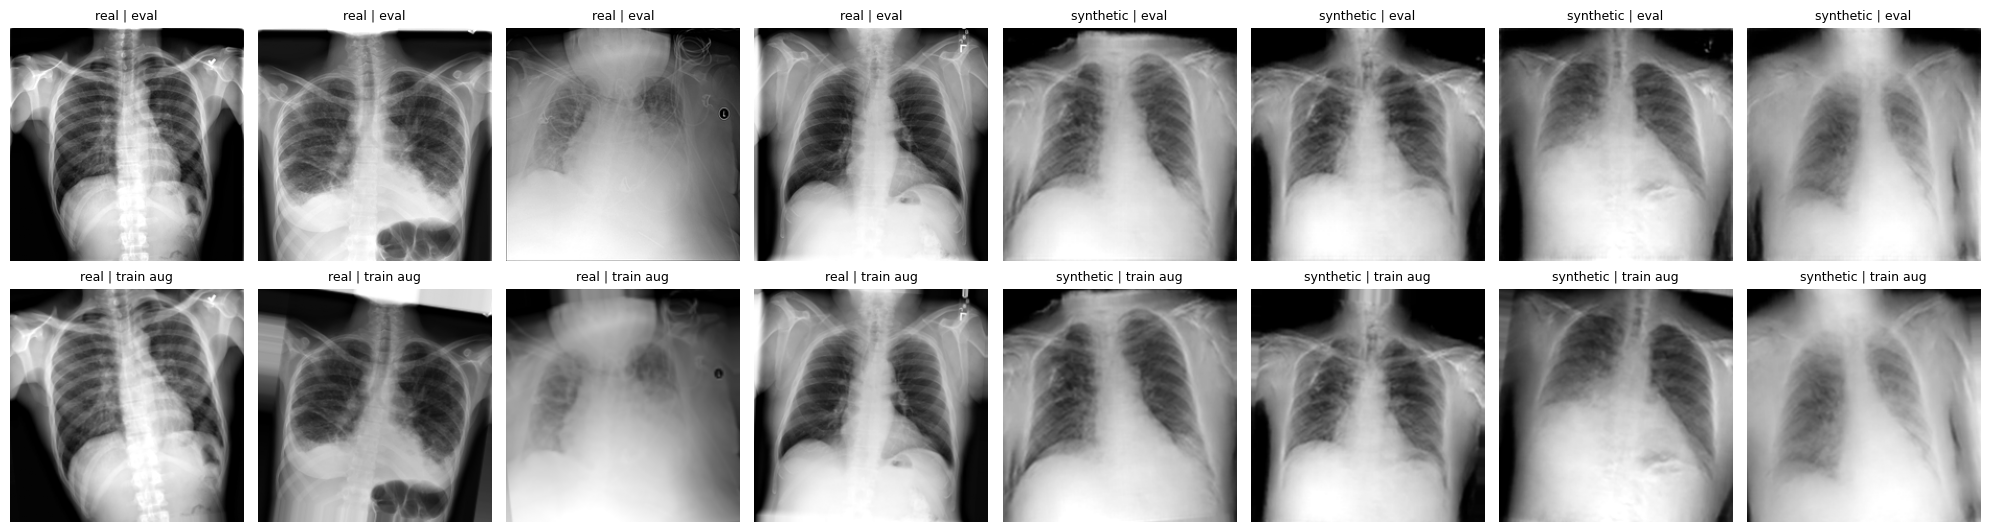

In [6]:
x, y, s = build_train(SCENARIOS['S3']); rs = np.random.RandomState(1)
ip = rs.choice(np.where((y == 1) & s)[0], 4, replace=False); ir = rs.choice(np.where((y == 1) & ~s)[0], 4, replace=False); idx = np.r_[ir, ip]
xb = torch.from_numpy(x[idx]); isb = torch.from_numpy(s[idx])
with torch.no_grad(): a, b = prep(xb, isb, train=False), prep(xb, isb, train=True)
fig, ax = plt.subplots(2, 8, figsize=(20, 5.5))
for k in range(8):
    for r_, t in enumerate((a, b)):
        ax[r_, k].imshow(t[k, 0].cpu(), cmap='gray'); ax[r_, k].axis('off'); ax[r_, k].set_title(('synthetic' if isb[k] else 'real') + (' | train aug' if r_ else ' | eval'), fontsize=9)
plt.tight_layout(); plt.show(); del x

### 6. Model, Training and Evaluation Functions

TorchXRayVision DenseNet-121 (CheXpert weights) with its 1,024-dimensional pooled features and a new single-logit head. Balanced sampler: every batch is drawn with equal probability for the two classes. Early stopping on the AUROC of the full real validation set.

In [7]:
%pip install -q torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 67.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [8]:
import torchxrayvision as xrv

class Net(nn.Module):
    def __init__(self):
        super().__init__(); self.base = xrv.models.DenseNet(weights=WEIGHTS); self.drop = nn.Dropout(0.2); self.fc = nn.Linear(1024, 1)
    def forward(self, x): return self.fc(self.drop(self.base.features2(x))).squeeze(1)

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = prep(torch.from_numpy(X[i:i + bs]))
        with torch.autocast('cuda', dtype=torch.float16): out.append(torch.sigmoid(model(xb).float()).cpu())
    return torch.cat(out).numpy()

def youden(y, p):                                                 # threshold maximising sensitivity + specificity - 1
    ts = np.unique(np.quantile(p, np.linspace(0, 1, 2001))); P, N = (y == 1).sum(), (y == 0).sum()
    j = [((p >= t) & (y == 1)).sum() / P + ((p < t) & (y == 0)).sum() / N - 1 for t in ts]; return float(ts[int(np.argmax(j))])

def train_run(name, cfg, seed):
    set_seed(seed); X, y, syn = build_train(cfg); yt, st = torch.from_numpy(y), torch.from_numpy(syn)
    w = np.where(y == 1, 0.5 / (y == 1).sum(), 0.5 / (y == 0).sum()); w = torch.from_numpy(w).float()      # class-balanced sampling weights
    gen = torch.Generator().manual_seed(seed)
    model = Net().to(DEVICE); opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD); scaler = torch.cuda.amp.GradScaler()
    total = MAX_EPOCHS * STEPS_PER_EPOCH
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / WARMUP) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(s, total) / total))))
    best, best_state, bad, log, t0 = -1, None, 0, [], time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); tl, sf = 0.0, 0.0
        for _ in range(STEPS_PER_EPOCH):
            ib = torch.multinomial(w, BATCH, replacement=True, generator=gen)
            xb = prep(torch.from_numpy(X[ib.numpy()]), st[ib], train=True); yb = yt[ib].to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16): loss = F.binary_cross_entropy_with_logits(model(xb).float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item(); sf += st[ib][yt[ib] == 1].float().mean().item() if (yt[ib] == 1).any() else 0
        pv = predict(model, XV); auc = roc_auc_score(IV.label.values, pv)
        log.append({'epoch': ep, 'train_loss': tl / STEPS_PER_EPOCH, 'synthetic_share_in_positives': sf / STEPS_PER_EPOCH, 'val_auc': auc, 'minutes': (time.time() - t0) / 60})
        print(f'  {name} seed {seed} | epoch {ep:2d} | loss {tl / STEPS_PER_EPOCH:.3f} | val AUROC {auc:.4f}' + (' *' if auc > best else ''))
        if auc > best: best, best_state, best_pv, bad, best_ep = auc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, pv, 0, ep
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state); thr = youden(IV.label.values, best_pv); pt = predict(model, XT)
    rows = [pd.DataFrame({'split': 'val', 'image': IV.image.values, 'prob': best_pv}), pd.DataFrame({'split': 'test', 'image': IT.image.values, 'prob': pt})]
    syn_means = {}
    for g, (Xs, Is) in SYN.items():                                # synthetic No Finding images NOT used in training: a model that learned "synthetic = pneumonia" scores them high
        if cfg.get('syn') == g and cfg.get('n_neg', 0) > 0: syn_means[g] = np.nan; continue
        m = (Is.label == 0).values; ps = predict(model, Xs[m]); syn_means[g] = float(ps.mean())
        rows.append(pd.DataFrame({'split': f'synneg_{g}', 'image': Is.image.values[m], 'prob': ps}))
    pd.concat(rows).to_csv(WORK / 'preds' / f'{name}_seed{seed}.csv.gz', index=False)
    pd.DataFrame(log).to_csv(WORK / 'curves' / f'{name}_seed{seed}.csv', index=False)
    cl, yv = IT.clean.values, IT.label.values
    return {'scenario': name, 'seed': seed, 'n_train': len(y), 'n_syn_pos': int((syn & (y == 1)).sum()), 'n_syn_neg': int((syn & (y == 0)).sum()),
            'best_epoch': best_ep, 'epochs_run': len(log), 'val_auc': best, 'threshold': thr,
            'test_clean_auc': roc_auc_score(yv[cl], pt[cl]), 'test_full_auc': roc_auc_score(yv, pt),
            'mean_prob_test_real_neg': float(pt[(yv == 0) & cl].mean()), 'mean_prob_synneg_dcgan': syn_means['dcgan'], 'mean_prob_synneg_roentgen': syn_means['roentgen'],
            'minutes': (time.time() - t0) / 60}

### 7. Run

Each run saves its predictions as soon as it finishes. One of the last columns of `runs_summary.csv`, `mean_prob_synneg_*`, is the shortcut diagnostic: the mean predicted probability of pneumonia on **synthetic No Finding images not used in training**. Compared with the mean on real No Finding test images (`mean_prob_test_real_neg`), a clearly higher value means that the model has learned to associate "synthetic" with pneumonia. A Kaggle commit run is lost if it fails, so run few scenarios per session if the time limit is a concern (one run takes about 5-12 minutes on a T4).

In [9]:
SUMMARY = WORK / 'runs_summary.csv'
summ = pd.read_csv(SUMMARY) if SUMMARY.exists() else pd.DataFrame()
for name in RUN:
    for seed in SEEDS:
        if SKIP_EXISTING and (WORK / 'preds' / f'{name}_seed{seed}.csv.gz').exists(): print('skip', name, seed); continue
        r = train_run(name, SCENARIOS[name], seed); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()}, '\n')
        summ = pd.concat([summ[~((summ.scenario == name) & (summ.seed == seed))] if len(summ) else summ, pd.DataFrame([r])], ignore_index=True); summ.to_csv(SUMMARY, index=False)

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
  S1 seed 0 | epoch  1 | loss 0.683 | val AUROC 0.6928 *
  S1 seed 0 | epoch  2 | loss 0.630 | val AUROC 0.7183 *
  S1 seed 0 | epoch  3 | loss 0.587 | val AUROC 0.7241 *
  S1 seed 0 | epoch  4 | loss 0.568 | val AUROC 0.7253 *
  S1 seed 0 | epoch  5 | loss 0.548 | val AUROC 0.7238
  S1 seed 0 | epoch  6 | loss 0.545 | val AUROC 0.7212
  S1 seed 0 | epoch  7 | loss 0.529 | val AUROC 0.7225
  S1 seed 0 | epoch  8 | loss 0.532 | val AUROC 0.7210
{'scenario': 'S1', 'seed': 0, 'n_train': 5000, 'n_syn_pos': 0, 'n_syn_neg': 0, 'best_epoch': 4, 'epochs_run': 8, 'val_auc': np.float64(0.7253), 'threshold': 0.5977, 'test_clean_auc': np.float64(0.7243), 'test_full_auc': np.float64(0.6139), 'mea

### 8. Summary

In [10]:
summ = pd.read_csv(SUMMARY)
cols = ['val_auc', 'test_clean_auc', 'test_full_auc', 'mean_prob_test_real_neg', 'mean_prob_synneg_dcgan', 'mean_prob_synneg_roentgen', 'best_epoch', 'minutes']
pd.set_option('display.width', 220); print(summ.groupby('scenario')[cols].mean().round(4).to_string()); print('\n', summ.round(4).to_string(index=False))

          val_auc  test_clean_auc  test_full_auc  mean_prob_test_real_neg  mean_prob_synneg_dcgan  mean_prob_synneg_roentgen  best_epoch  minutes
scenario                                                                                                                                         
S1         0.7293          0.7269         0.6162                   0.4836                  0.4122                     0.3514      4.0000   7.2754
S2         0.6938          0.6861         0.5874                   0.4038                     NaN                     0.2906      2.0000   5.6130
S3         0.6771          0.6694         0.5692                   0.4530                  0.4351                     0.3825      1.0000   4.8593
S4         0.4681          0.5275         0.5053                   0.4225                  0.4788                        NaN      5.0000   8.0351
S5         0.6846          0.6707         0.5885                   0.1757                  0.1279                     0.9758